# RAJUK Balanced Bagged Random Forest — CUDA Feature Edition

This notebook replaces the leaky flattened-pixel/PCA search with a stronger and more honest pipeline:

- subject-level train/validation/test splitting, so augmented copies of one original never cross splits;
- random sampling without replacement with the **same number of real, augmented, and total training images in every class**;
- CUDA-accelerated ImageNet ResNet18 embeddings (the tree ensembles themselves run on CPU);
- bootstrapped Random Forest and Extra Trees models combined by validation-selected soft voting;
- full error report, classification report, confusion matrices, misclassified-image CSV files, and bias–variance plots.

> Run the cells from top to bottom. The notebook always saves the trained result and reports gains/losses against the old notebook; it does not raise an exception when a reference score is missed.

## 1. Imports, paths, and reproducibility

In [1]:
import gc
import re
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, log_loss,
    classification_report, confusion_matrix
)

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

ROOT_HINT = Path(r'D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files')
root_candidates = [Path.cwd(), Path.cwd().parent, ROOT_HINT]
PROJECT_ROOT = next(
    (path.resolve() for path in root_candidates
     if (path / 'Augmented_raw_data').exists() and (path / 'raw_data').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate the project root containing raw_data and Augmented_raw_data.')

AUGMENTED_DIR = PROJECT_ROOT / 'Augmented_raw_data'
REAL_DIR = PROJECT_ROOT / 'raw_data' / 'final train image'
CSV_PATH = PROJECT_ROOT / 'Real ML_DataSet.csv'
XLSX_CANDIDATES = [PROJECT_ROOT / 'Real ML_DataSet.xlsx', PROJECT_ROOT / 'Rajuk_ML_DataSet.xlsx']
OUTPUT_DIR = PROJECT_ROOT / 'Random_Forest'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['negative', 'moderate', 'positive']
ALLOWED_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
TEST_FRACTION = 0.20
VAL_FRACTION = 0.10
RANDOM_IMAGES_PER_CLASS = 700
RANDOM_REAL_IMAGES_PER_CLASS = 40
DEEP_BATCH_SIZE = 32
DATALOADER_WORKERS = 0
MAX_TREES_PER_COMPONENT_FOR_BIAS_VARIANCE = 60

REFERENCE_TEST_ACCURACY = 0.5417
REFERENCE_TEST_MACRO_F1 = 0.2400

MODEL_PATH = OUTPUT_DIR / 'rajuk_balanced_bagged_random_forest.pkl'
TEST_MISCLASSIFIED_CSV = OUTPUT_DIR / 'misclassified_images_random_forest.csv'
VAL_MISCLASSIFIED_CSV = OUTPUT_DIR / 'val_misclassified_random_forest.csv'
BIAS_VARIANCE_PNG = OUTPUT_DIR / 'bias_variance_random_forest.png'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Project root       : {PROJECT_ROOT}')
print(f'Feature device     : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'CUDA GPU           : {torch.cuda.get_device_name(0)}')
    print(f'PyTorch CUDA build : {torch.version.cuda}')
else:
    print('CUDA was not detected; feature extraction will use CPU and will be slower.')
print('Tree training      : CPU (all available cores through n_jobs=-1)')
print(f'Output directory   : {OUTPUT_DIR}')

Project root       : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files
Feature device     : cuda
CUDA GPU           : NVIDIA GeForce GTX 1650
PyTorch CUDA build : 12.4
Tree training      : CPU (all available cores through n_jobs=-1)
Output directory   : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest


## 2. Load labels and create a subject-level split

Every augmented version inherits the split of its original `imgNN` subject. This prevents near-duplicate image leakage.

In [2]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(frame, *targets):
    normalized = {normalize_header(column): column for column in frame.columns}
    return next((normalized[target] for target in targets if target in normalized), None)

def normalize_level(value):
    if pd.isna(value):
        return None
    return {
        'n': 'negative', 'negative': 'negative',
        'm': 'moderate', 'moderate': 'moderate',
        'p': 'positive', 'positive': 'positive',
    }.get(str(value).strip().lower())

if CSV_PATH.exists():
    labels_df = pd.read_csv(CSV_PATH)
    label_source = CSV_PATH
else:
    label_source = next((path for path in XLSX_CANDIDATES if path.exists()), None)
    if label_source is None:
        raise FileNotFoundError('No CSV/XLSX label file was found.')
    labels_df = pd.read_excel(label_source)

level_column = find_column(labels_df, 'levelpositivemoderatenegative', 'level')
if level_column is None:
    raise ValueError(f'Could not find the level column. Columns: {list(labels_df.columns)}')

class_to_index = {name: index for index, name in enumerate(CLASS_NAMES)}
label_map = {}
for row_index, value in enumerate(labels_df[level_column].tolist(), start=1):
    level = normalize_level(value)
    if level is not None:
        label_map[row_index] = class_to_index[level]

def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.strip().lower())
    return int(match.group(1)) if match else None

def collect_records(directory):
    records, skipped = [], 0
    if not directory.exists():
        raise FileNotFoundError(directory)
    for path in sorted(directory.rglob('*')):
        if not (path.is_file() and path.suffix.lower() in ALLOWED_EXTS):
            continue
        image_id = parse_image_index(path.stem)
        if image_id is None or image_id not in label_map:
            skipped += 1
            continue
        records.append((path, label_map[image_id], image_id))
    return records, skipped

augmented_records, skipped_augmented = collect_records(AUGMENTED_DIR)
real_records, skipped_real = collect_records(REAL_DIR)
unique_ids = np.array(sorted({record[2] for record in real_records}))
unique_labels = np.array([label_map[image_id] for image_id in unique_ids])

trainval_ids, test_ids = train_test_split(
    unique_ids, test_size=TEST_FRACTION, random_state=SEED, stratify=unique_labels
)
trainval_labels = np.array([label_map[image_id] for image_id in trainval_ids])
train_ids, val_ids = train_test_split(
    trainval_ids,
    test_size=VAL_FRACTION / (1.0 - TEST_FRACTION),
    random_state=SEED,
    stratify=trainval_labels,
)
train_ids, val_ids, test_ids = set(train_ids), set(val_ids), set(test_ids)
all_records = augmented_records + real_records
train_records = [record for record in all_records if record[2] in train_ids]
val_records = [record for record in all_records if record[2] in val_ids]
test_records = [record for record in all_records if record[2] in test_ids]

assert train_ids.isdisjoint(val_ids | test_ids)
assert val_ids.isdisjoint(test_ids)

def record_distribution(name, records):
    counts = np.bincount([record[1] for record in records], minlength=len(CLASS_NAMES))
    print(f'\n{name}: {len(records):,} images from {len({r[2] for r in records}):,} subjects')
    for class_name, count in zip(CLASS_NAMES, counts):
        print(f'  {class_name:10s}: {count:,}')

print(f'Loaded labels    : {len(label_map):,} from {label_source.name}')
print(f'Augmented images : {len(augmented_records):,}')
print(f'Real images      : {len(real_records):,}')
print(f'Skipped files    : {skipped_augmented + skipped_real:,}')
record_distribution('Training before balancing', train_records)
record_distribution('Validation', val_records)
record_distribution('Test', test_records)

Loaded labels    : 372 from Real ML_DataSet.csv
Augmented images : 5,968
Real images      : 373
Skipped files    : 17

Training before balancing: 4,420 images from 259 subjects
  negative  : 2,720
  moderate  : 969
  positive  : 731

Validation: 646 images from 38 subjects
  negative  : 408
  moderate  : 136
  positive  : 102

Test: 1,275 images from 75 subjects
  negative  : 782
  moderate  : 289
  positive  : 204


## 3. Extract robust ResNet18 embeddings

The pretrained backbone is frozen. CUDA is used automatically when available; only compact 512-dimensional embeddings are copied back to RAM.

In [3]:
resnet_weights = models.ResNet18_Weights.DEFAULT
image_transform = resnet_weights.transforms()
resnet_backbone = models.resnet18(weights=resnet_weights)
resnet_backbone.fc = torch.nn.Identity()
resnet_backbone = resnet_backbone.to(DEVICE).eval()
for parameter in resnet_backbone.parameters():
    parameter.requires_grad = False

class ImageRecordDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path, label, image_id = self.records[index]
        with Image.open(path) as image:
            tensor = image_transform(image.convert('RGB'))
        return tensor, label, image_id, str(path)

def extract_embeddings(records, split_name):
    loader = DataLoader(
        ImageRecordDataset(records), batch_size=DEEP_BATCH_SIZE, shuffle=False,
        num_workers=DATALOADER_WORKERS, pin_memory=(DEVICE.type == 'cuda')
    )
    features, labels, groups, paths = [], [], [], []
    processed = 0
    with torch.inference_mode():
        for images, batch_labels, batch_groups, batch_paths in loader:
            images = images.to(DEVICE, non_blocking=True)
            if DEVICE.type == 'cuda':
                with torch.autocast(device_type='cuda', dtype=torch.float16):
                    embeddings = resnet_backbone(images)
            else:
                embeddings = resnet_backbone(images)
            embeddings = F.normalize(embeddings.float(), p=2, dim=1)
            features.append(embeddings.cpu().numpy().astype(np.float32))
            labels.append(batch_labels.numpy().astype(np.int64))
            groups.append(batch_groups.numpy().astype(np.int64))
            paths.extend(batch_paths)
            processed += len(images)
            print(f'  {split_name}: {processed:,}/{len(records):,}', end='\r')
    print()
    return (
        np.concatenate(features), np.concatenate(labels), np.concatenate(groups),
        [Path(path) for path in paths]
    )

X_train_all, y_train_all, train_groups, train_paths = extract_embeddings(train_records, 'train')
X_val, y_val, val_groups, val_paths = extract_embeddings(val_records, 'validation')
X_test, y_test, test_groups, test_paths = extract_embeddings(test_records, 'test')
print(f'Embedding shapes: train={X_train_all.shape}, val={X_val.shape}, test={X_test.shape}')

  train: 4,420/4,420
  validation: 646/646
  test: 1,275/1,275
Embedding shapes: train=(4420, 512), val=(646, 512), test=(1275, 512)


## 4. Random source-balanced training selection

Each class receives exactly the same feasible number of unique real files and unique augmented files. Sampling is random, reproducible, and without replacement.

In [4]:
def make_random_source_balanced(X, y, groups, paths, random_state, requested_per_class=RANDOM_IMAGES_PER_CLASS):
    rng = np.random.default_rng(random_state)
    augmented_root = AUGMENTED_DIR.resolve()

    def path_is_augmented(path):
        try:
            return Path(path).resolve().is_relative_to(augmented_root)
        except Exception:
            return 'aug' in str(path).lower()

    augmented_flags = np.asarray([path_is_augmented(path) for path in paths], dtype=bool)
    real_counts = np.asarray([
        np.sum((y == class_index) & ~augmented_flags) for class_index in range(len(CLASS_NAMES))
    ], dtype=int)
    augmented_counts = np.asarray([
        np.sum((y == class_index) & augmented_flags) for class_index in range(len(CLASS_NAMES))
    ], dtype=int)

    real_per_class = min(int(RANDOM_REAL_IMAGES_PER_CLASS), int(real_counts.min()))
    per_class = min(int(requested_per_class), int(real_per_class + augmented_counts.min()))
    augmented_per_class = per_class - real_per_class
    if real_per_class < 1 or augmented_per_class < 1:
        raise ValueError('Every class needs at least one real and one augmented training image.')

    selected_parts = []
    for class_index in range(len(CLASS_NAMES)):
        real_candidates = np.flatnonzero((y == class_index) & ~augmented_flags)
        augmented_candidates = np.flatnonzero((y == class_index) & augmented_flags)
        selected_parts.append(rng.choice(real_candidates, size=real_per_class, replace=False))
        selected_parts.append(rng.choice(augmented_candidates, size=augmented_per_class, replace=False))

    selected = np.concatenate(selected_parts)
    if len(np.unique(selected)) != len(selected):
        raise AssertionError('Duplicate file indices were selected.')
    rng.shuffle(selected)

    balanced_y = y[selected]
    selected_augmented = augmented_flags[selected]
    selected_real_counts = np.asarray([
        np.sum((balanced_y == index) & ~selected_augmented) for index in range(len(CLASS_NAMES))
    ])
    selected_augmented_counts = np.asarray([
        np.sum((balanced_y == index) & selected_augmented) for index in range(len(CLASS_NAMES))
    ])
    total_counts = np.bincount(balanced_y, minlength=len(CLASS_NAMES))
    assert len(set(total_counts.tolist())) == 1
    assert len(set(selected_real_counts.tolist())) == 1
    assert len(set(selected_augmented_counts.tolist())) == 1

    summary = {
        'available_real': real_counts, 'available_augmented': augmented_counts,
        'selected_real': selected_real_counts,
        'selected_augmented': selected_augmented_counts,
        'selected_total': total_counts,
    }
    return X[selected], y[selected], groups[selected], [paths[i] for i in selected], selected, summary

(
    X_train, y_train, train_groups_balanced, train_paths_balanced,
    train_balance_indices, train_source_summary,
) = make_random_source_balanced(
    X_train_all, y_train_all, train_groups, train_paths, random_state=SEED
)

balance_table = pd.DataFrame({
    'class': CLASS_NAMES,
    'before_total': np.bincount(y_train_all, minlength=len(CLASS_NAMES)),
    'available_real': train_source_summary['available_real'],
    'available_augmented': train_source_summary['available_augmented'],
    'selected_real': train_source_summary['selected_real'],
    'selected_augmented': train_source_summary['selected_augmented'],
    'after_total': train_source_summary['selected_total'],
})
display(balance_table)
print(
    f'BALANCE CONFIRMED: {train_source_summary["selected_real"][0]:,} real + '
    f'{train_source_summary["selected_augmented"][0]:,} augmented = '
    f'{train_source_summary["selected_total"][0]:,} unique images per class.'
)

,class,before_total,available_real,available_augmented,selected_real,selected_augmented,after_total
0,negative,2720,160,2560,40,660,700
1,moderate,969,57,912,40,660,700
2,positive,731,43,688,40,660,700


BALANCE CONFIRMED: 40 real + 660 augmented = 700 unique images per class.


## 5. Select a bootstrapped tree ensemble

Random Forest is already a bagging method. The candidates below also include randomized Extra Trees with bootstrap sampling. Selection prioritizes subject-level macro-F1, then balanced accuracy and accuracy—not the misleading image-level CV score from the old notebook.

In [5]:
TREE_CANDIDATES = [
    dict(name='RF-wide', family='rf', n_estimators=700, max_depth=None,
         min_samples_leaf=1, max_features='sqrt', max_samples=0.90),
    dict(name='RF-regularized', family='rf', n_estimators=800, max_depth=32,
         min_samples_leaf=2, max_features=0.40, max_samples=0.85),
    dict(name='ET-wide', family='extra', n_estimators=700, max_depth=None,
         min_samples_leaf=1, max_features='sqrt', max_samples=0.90),
    dict(name='ET-regularized', family='extra', n_estimators=800, max_depth=36,
         min_samples_leaf=2, max_features=0.45, max_samples=0.85),
]

def build_tree_model(config, random_state):
    common = dict(
        n_estimators=config['n_estimators'], max_depth=config['max_depth'],
        min_samples_leaf=config['min_samples_leaf'], max_features=config['max_features'],
        bootstrap=True, max_samples=config['max_samples'], oob_score=True,
        class_weight=None, random_state=random_state, n_jobs=-1,
    )
    if config['family'] == 'rf':
        return RandomForestClassifier(criterion='entropy', **common)
    return ExtraTreesClassifier(criterion='entropy', **common)

def aggregate_probabilities_by_subject(probabilities, labels, groups):
    rows = []
    for group in np.unique(groups):
        mask = groups == group
        rows.append((group, int(labels[mask][0]), probabilities[mask].mean(axis=0)))
    subject_labels = np.asarray([row[1] for row in rows], dtype=np.int64)
    subject_probabilities = np.stack([row[2] for row in rows])
    return subject_labels, subject_probabilities

def metric_row(labels, probabilities):
    predictions = probabilities.argmax(axis=1)
    return {
        'macro_f1': f1_score(labels, predictions, average='macro', zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(labels, predictions),
        'accuracy': accuracy_score(labels, predictions),
        'log_loss': log_loss(labels, probabilities, labels=np.arange(len(CLASS_NAMES))),
    }

candidate_rows = []
for candidate_index, config in enumerate(TREE_CANDIDATES, start=1):
    print(f'Candidate {candidate_index}/{len(TREE_CANDIDATES)}: {config["name"]}')
    candidate = build_tree_model(config, SEED + candidate_index)
    candidate.fit(X_train, y_train)
    val_probability = candidate.predict_proba(X_val)
    subject_y, subject_probability = aggregate_probabilities_by_subject(
        val_probability, y_val, val_groups
    )
    row = {'candidate_index': candidate_index - 1, 'name': config['name'],
           'family': config['family'], 'oob_accuracy': candidate.oob_score_}
    row.update(metric_row(subject_y, subject_probability))
    candidate_rows.append(row)
    del candidate
    gc.collect()

candidate_results = pd.DataFrame(candidate_rows).sort_values(
    ['macro_f1', 'balanced_accuracy', 'accuracy'], ascending=False
).reset_index(drop=True)
display(candidate_results)

selected_candidate_indices = candidate_results.head(3)['candidate_index'].astype(int).tolist()
selected_configs = [TREE_CANDIDATES[index] for index in selected_candidate_indices]
selection_models = []
for model_index, config in enumerate(selected_configs):
    print(f'Refitting selected component: {config["name"]}')
    model = build_tree_model(config, SEED + 100 + model_index)
    model.fit(X_train, y_train)
    selection_models.append(model)

def ensemble_predict_proba(component_models, weights, X):
    weights = np.asarray(weights, dtype=np.float64)
    weights = weights / weights.sum()
    return np.average(
        np.stack([model.predict_proba(X) for model in component_models]),
        axis=0, weights=weights
    )

component_val_probabilities = [model.predict_proba(X_val) for model in selection_models]
weight_candidates = []
for first in np.arange(0.0, 1.01, 0.25):
    for second in np.arange(0.0, 1.01 - first, 0.25):
        third = 1.0 - first - second
        if third >= -1e-9:
            weight_candidates.append(np.asarray([first, second, max(0.0, third)]))

blend_rows = []
for weights in weight_candidates:
    probabilities = np.average(np.stack(component_val_probabilities), axis=0, weights=weights)
    subject_y, subject_probabilities = aggregate_probabilities_by_subject(
        probabilities, y_val, val_groups
    )
    row = {'weights': weights}
    row.update(metric_row(subject_y, subject_probabilities))
    blend_rows.append(row)

best_blend = sorted(
    blend_rows,
    key=lambda row: (row['macro_f1'], row['balanced_accuracy'], row['accuracy'], -row['log_loss']),
    reverse=True,
)[0]
selected_weights = best_blend['weights']
val_probabilities = ensemble_predict_proba(selection_models, selected_weights, X_val)
val_predictions = val_probabilities.argmax(axis=1)
print(f'Selected components: {[config["name"] for config in selected_configs]}')
print(f'Soft-voting weights: {selected_weights}')
print(f'Validation subject macro-F1: {best_blend["macro_f1"]:.4f}')
print(f'Validation image accuracy  : {accuracy_score(y_val, val_predictions):.4f}')

# Cache a small, weighted sample of validation predictions for the later
# bias-variance graph, then release the full selection models before final fitting.
bias_member_probabilities = []
bias_member_weights = []
for component_model, component_weight in zip(selection_models, selected_weights):
    if component_weight <= 0:
        continue
    tree_count = min(MAX_TREES_PER_COMPONENT_FOR_BIAS_VARIANCE, len(component_model.estimators_))
    tree_indices = np.linspace(0, len(component_model.estimators_) - 1, tree_count, dtype=int)
    for tree_index in tree_indices:
        tree = component_model.estimators_[tree_index]
        raw_probability = tree.predict_proba(X_val)
        aligned_probability = np.zeros((len(X_val), len(CLASS_NAMES)), dtype=np.float64)
        for probability_column, class_index in enumerate(tree.classes_.astype(int)):
            aligned_probability[:, class_index] = raw_probability[:, probability_column]
        bias_member_probabilities.append(aligned_probability)
        bias_member_weights.append(float(component_weight) / tree_count)
bias_member_probabilities = np.stack(bias_member_probabilities)
bias_member_weights = np.asarray(bias_member_weights, dtype=np.float64)
bias_member_weights /= bias_member_weights.sum()
del selection_models, component_val_probabilities
gc.collect()

Candidate 1/4: RF-wide
Candidate 2/4: RF-regularized
Candidate 3/4: ET-wide
Candidate 4/4: ET-regularized


,candidate_index,name,family,oob_accuracy,macro_f1,balanced_accuracy,accuracy,log_loss
0,0,RF-wide,rf,0.223333,0.619048,0.666667,0.789474,1.079790
1,1,RF-regularized,rf,0.206667,0.619048,0.666667,0.789474,1.084326
2,2,ET-wide,extra,0.190952,0.619048,0.666667,0.789474,1.084602
3,3,ET-regularized,extra,0.251429,0.466667,0.666667,0.368421,1.093813


Refitting selected component: RF-wide
Refitting selected component: RF-regularized
Refitting selected component: ET-wide
Selected components: ['RF-wide', 'RF-regularized', 'ET-wide']
Soft-voting weights: [0.25 0.75 0.  ]
Validation subject macro-F1: 0.6190
Validation image accuracy  : 0.6409


192

## 6. Final balanced refit and test evaluation

After model/weight selection, training and validation are combined, randomly rebalanced with identical source composition per class, and the selected bagged components are refit once.

In [6]:
X_trainval_all = np.vstack([X_train_all, X_val])
y_trainval_all = np.concatenate([y_train_all, y_val])
trainval_groups_all = np.concatenate([train_groups, val_groups])
trainval_paths_all = train_paths + val_paths

(
    X_trainval, y_trainval, trainval_groups, trainval_paths,
    final_balance_indices, final_source_summary,
) = make_random_source_balanced(
    X_trainval_all, y_trainval_all, trainval_groups_all, trainval_paths_all,
    random_state=SEED + 1000
)

final_models = []
for model_index, config in enumerate(selected_configs):
    print(f'Final fit: {config["name"]}')
    model = build_tree_model(config, SEED + 2000 + model_index)
    model.fit(X_trainval, y_trainval)
    final_models.append(model)

train_probabilities = ensemble_predict_proba(final_models, selected_weights, X_trainval)
train_predictions = train_probabilities.argmax(axis=1)
test_probabilities = ensemble_predict_proba(final_models, selected_weights, X_test)
test_predictions = test_probabilities.argmax(axis=1)

test_accuracy = accuracy_score(y_test, test_predictions)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(y_test, test_predictions, average='macro', zero_division=0)
test_log_loss = log_loss(y_test, test_probabilities, labels=np.arange(len(CLASS_NAMES)))

augmented_root = AUGMENTED_DIR.resolve()
def is_augmented_path(path):
    try:
        return Path(path).resolve().is_relative_to(augmented_root)
    except Exception:
        return 'aug' in str(path).lower()

test_real_mask = np.asarray([not is_augmented_path(path) for path in test_paths])
test_real_y = y_test[test_real_mask]
test_real_probabilities = test_probabilities[test_real_mask]
test_real_predictions = test_predictions[test_real_mask]
test_real_accuracy = accuracy_score(test_real_y, test_real_predictions)
test_real_balanced_accuracy = balanced_accuracy_score(test_real_y, test_real_predictions)
test_real_macro_f1 = f1_score(test_real_y, test_real_predictions, average='macro', zero_division=0)

test_subject_y, test_subject_probabilities = aggregate_probabilities_by_subject(
    test_probabilities, y_test, test_groups
)
test_subject_metrics = metric_row(test_subject_y, test_subject_probabilities)

print('\nFINAL TEST METRICS')
print('-' * 60)
print(f'Image accuracy          : {test_accuracy:.4f}')
print(f'Image balanced accuracy : {test_balanced_accuracy:.4f}')
print(f'Image macro-F1          : {test_macro_f1:.4f}')
print(f'Image log loss          : {test_log_loss:.4f}')
print(f'Subject accuracy        : {test_subject_metrics["accuracy"]:.4f}')
print(f'Subject macro-F1        : {test_subject_metrics["macro_f1"]:.4f}')
print(f'Real-only accuracy      : {test_real_accuracy:.4f}')
print(f'Real-only macro-F1      : {test_real_macro_f1:.4f}')
print(f'Real accuracy vs old RF : {test_real_accuracy - REFERENCE_TEST_ACCURACY:+.4f}')
print(f'Real macro-F1 vs old RF : {test_real_macro_f1 - REFERENCE_TEST_MACRO_F1:+.4f}')

Final fit: RF-wide
Final fit: RF-regularized
Final fit: ET-wide

FINAL TEST METRICS
------------------------------------------------------------
Image accuracy          : 0.2361
Image balanced accuracy : 0.3529
Image macro-F1          : 0.1600
Image log loss          : 1.1515
Subject accuracy        : 0.3867
Subject macro-F1        : 0.3795
Real-only accuracy      : 0.3867
Real-only macro-F1      : 0.3795
Real accuracy vs old RF : -0.1550
Real macro-F1 vs old RF : +0.1395


## 7. Classification report, confusion matrices, and final error report

Test Set — Classification Report
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       782
    moderate       0.23      1.00      0.38       289
    positive       0.44      0.06      0.10       204

    accuracy                           0.24      1275
   macro avg       0.23      0.35      0.16      1275
weighted avg       0.12      0.24      0.10      1275

Real-only Test Set — Classification Report
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        46
    moderate       0.35      1.00      0.52        17
    positive       0.44      1.00      0.62        12

    accuracy                           0.39        75
   macro avg       0.27      0.67      0.38        75
weighted avg       0.15      0.39      0.22        75



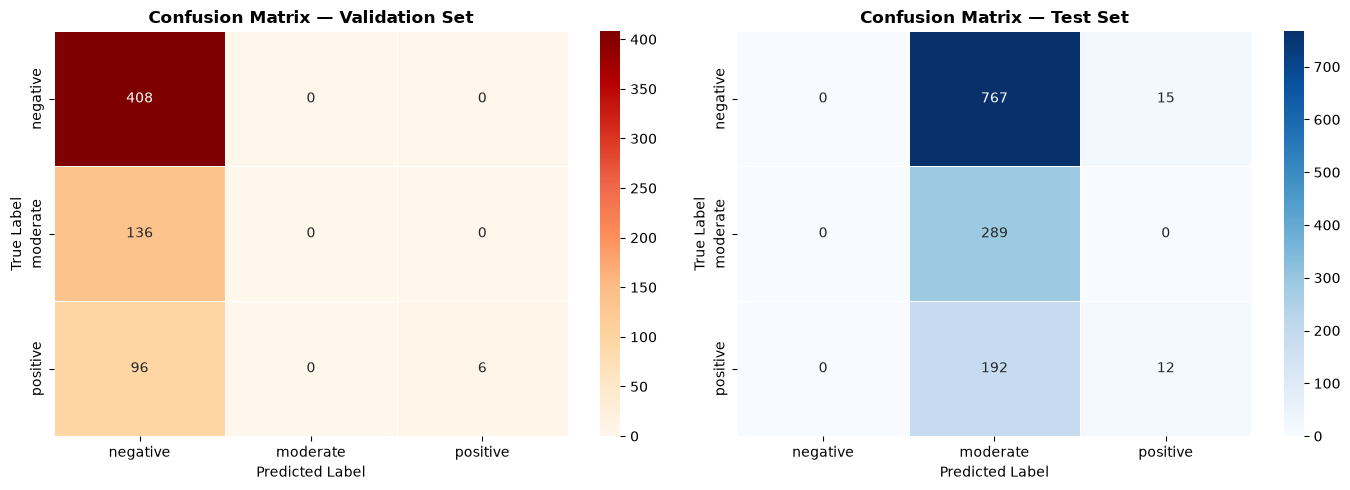

  FINAL ERROR REPORT — balanced bootstrapped tree soft-voting ensemble
  Split          Samples         Loss     Accuracy        Error
  --------------------------------------------------------------------
  Training         2,100       1.0939      33.76%       66.24%
  Validation         646       1.0883      64.09%       35.91%
  Test             1,275       1.1515      23.61%       76.39%


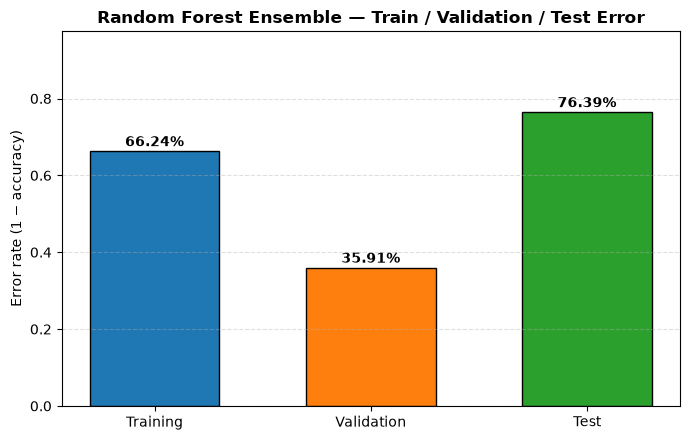

Classification CSV : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\test_classification_report_random_forest.csv
Confusion plot     : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\confusion_matrices_random_forest.png
Error report CSV   : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\final_error_report_random_forest.csv
Error report plot  : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\final_error_report_random_forest.png


In [7]:
print('Test Set — Classification Report')
print('─' * 60)
print(classification_report(
    y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0
))
print('Real-only Test Set — Classification Report')
print('─' * 60)
print(classification_report(
    test_real_y, test_real_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0
))

classification_report_df = pd.DataFrame(classification_report(
    y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0, output_dict=True
)).T
classification_report_path = OUTPUT_DIR / 'test_classification_report_random_forest.csv'
classification_report_df.to_csv(classification_report_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, predictions, labels, title, colour_map in [
    (axes[0], val_predictions, y_val, 'Confusion Matrix — Validation Set', 'OrRd'),
    (axes[1], test_predictions, y_test, 'Confusion Matrix — Test Set', 'Blues'),
]:
    matrix = confusion_matrix(labels, predictions, labels=np.arange(len(CLASS_NAMES)))
    sns.heatmap(
        matrix, annot=True, fmt='d', cmap=colour_map,
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        linewidths=0.5, ax=ax
    )
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
plt.tight_layout()
confusion_path = OUTPUT_DIR / 'confusion_matrices_random_forest.png'
plt.savefig(confusion_path, dpi=150, bbox_inches='tight')
plt.show()

train_loss = log_loss(y_trainval, train_probabilities, labels=np.arange(len(CLASS_NAMES)))
train_accuracy = accuracy_score(y_trainval, train_predictions)
val_loss = log_loss(y_val, val_probabilities, labels=np.arange(len(CLASS_NAMES)))
val_accuracy = accuracy_score(y_val, val_predictions)
report_rows = [
    ('Training', len(y_trainval), train_loss, train_accuracy, 1 - train_accuracy),
    ('Validation', len(y_val), val_loss, val_accuracy, 1 - val_accuracy),
    ('Test', len(y_test), test_log_loss, test_accuracy, 1 - test_accuracy),
]

print('=' * 74)
print('  FINAL ERROR REPORT — balanced bootstrapped tree soft-voting ensemble')
print('=' * 74)
print(f'  {"Split":<12}{"Samples":>10}{"Loss":>13}{"Accuracy":>13}{"Error":>13}')
print('  ' + '-' * 68)
for split_name, sample_count, loss_value, accuracy_value, error_value in report_rows:
    print(
        f'  {split_name:<12}{sample_count:>10,}{loss_value:>13.4f}'
        f'{accuracy_value:>12.2%}{error_value:>13.2%}'
    )
print('=' * 74)

final_error_df = pd.DataFrame(
    report_rows, columns=['split', 'samples', 'loss', 'accuracy', 'error']
)
final_error_csv = OUTPUT_DIR / 'final_error_report_random_forest.csv'
final_error_df.to_csv(final_error_csv, index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    final_error_df['split'], final_error_df['error'],
    color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black', width=0.6
)
for bar, error_rate in zip(bars, final_error_df['error']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{error_rate:.2%}', ha='center', va='bottom', fontweight='bold')
ax.set_ylabel('Error rate (1 − accuracy)')
ax.set_title('Random Forest Ensemble — Train / Validation / Test Error', fontweight='bold')
ax.set_ylim(0, max(final_error_df['error']) * 1.25 + 0.02)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
final_error_png = OUTPUT_DIR / 'final_error_report_random_forest.png'
plt.savefig(final_error_png, dpi=150, bbox_inches='tight')
plt.show()

print(f'Classification CSV : {classification_report_path}')
print(f'Confusion plot     : {confusion_path}')
print(f'Error report CSV   : {final_error_csv}')
print(f'Error report plot  : {final_error_png}')

## 8. Misclassified image reports

Both CSV files contain the image name, full path, subject ID, true/predicted labels, confidence, and all class probabilities.

Validation misclassified: 232/646
Validation CSV          : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\val_misclassified_random_forest.csv
Test misclassified      : 974/1,275
Test CSV                : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\misclassified_images_random_forest.csv


,split,split_index,image_name,image_path,image_id,image_type,true_label,predicted_label,error_type,confidence,probability_negative,probability_moderate,probability_positive
0,test,272,img108_autocontrast.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.335143,0.334769,0.335143,0.330089
1,test,273,img108_brightness_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.335143,0.334769,0.335143,0.330089
2,test,274,img108_brightness_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.335143,0.334769,0.335143,0.330089
3,test,275,img108_color_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.335143,0.334769,0.335143,0.330089
4,test,276,img108_color_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.335143,0.334769,0.335143,0.330089
...,...,...,...,...,...,...,...,...,...,...,...,...,...
969,test,1258,img75.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,75,real,negative,positive,negative -> positive,0.997478,0.001270,0.001251,0.997478
970,test,1259,img77.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,77,real,negative,positive,negative -> positive,0.997478,0.001270,0.001251,0.997478
971,test,1260,img80.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,80,real,negative,positive,negative -> positive,0.997478,0.001270,0.001251,0.997478
972,test,1261,img90.jpg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,90,real,negative,positive,negative -> positive,0.997478,0.001270,0.001251,0.997478


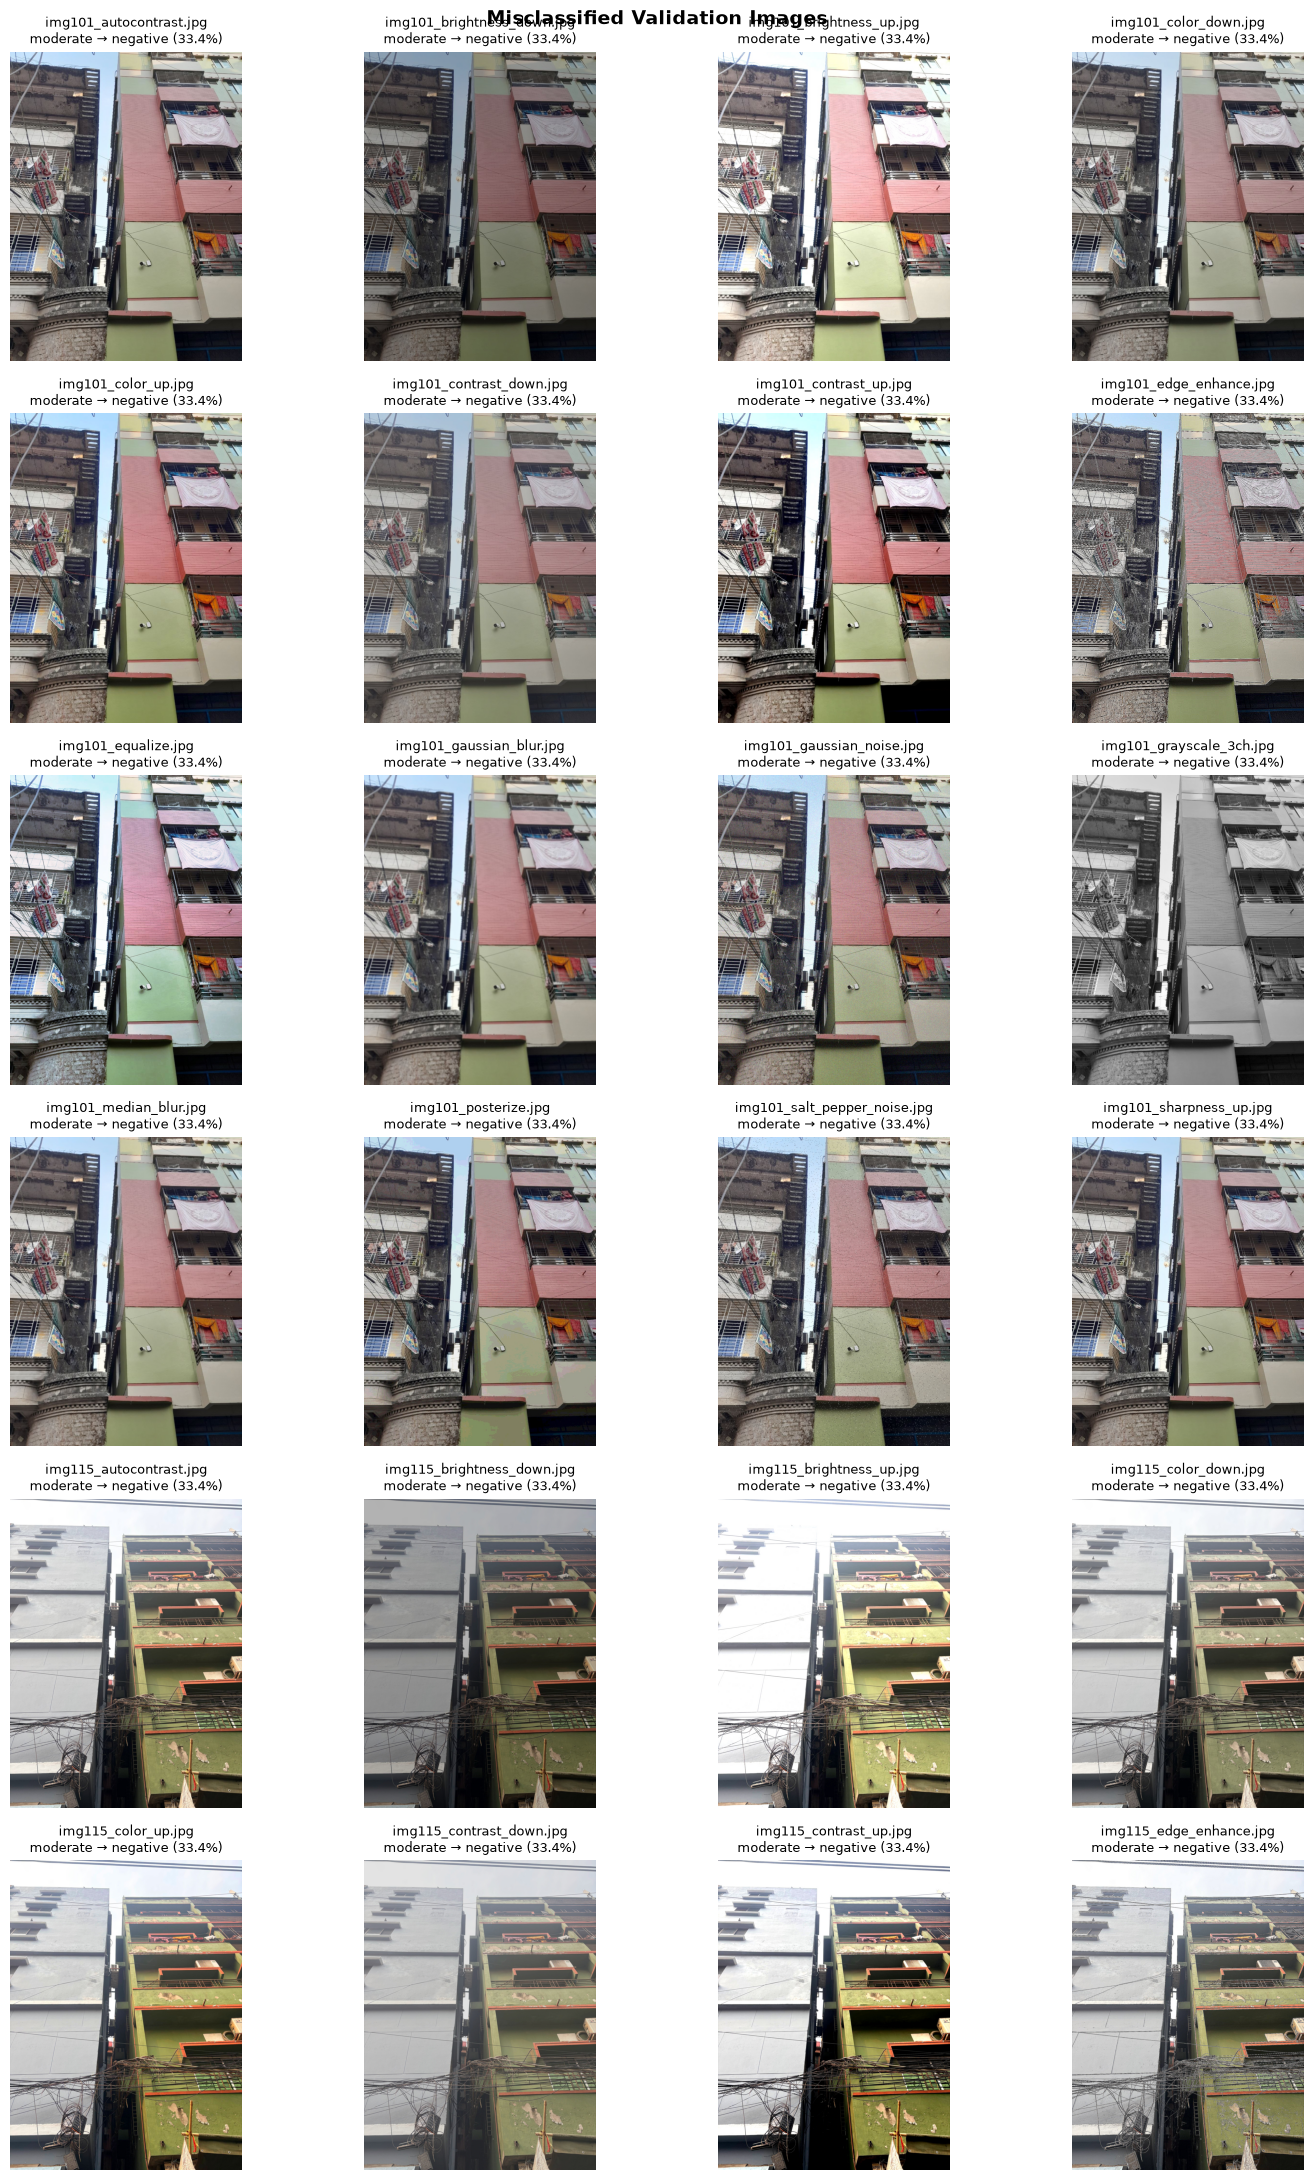

In [8]:
def build_misclassified_table(labels, predictions, probabilities, groups, paths, split_name):
    indices = np.flatnonzero(predictions != labels)
    rows = []
    augmented_root = AUGMENTED_DIR.resolve()
    for index in indices:
        path = Path(paths[index])
        try:
            image_type = 'augmented' if path.resolve().is_relative_to(augmented_root) else 'real'
        except Exception:
            image_type = 'augmented' if 'aug' in str(path).lower() else 'real'
        row = {
            'split': split_name, 'split_index': int(index), 'image_name': path.name,
            'image_path': str(path), 'image_id': int(groups[index]), 'image_type': image_type,
            'true_label': CLASS_NAMES[int(labels[index])],
            'predicted_label': CLASS_NAMES[int(predictions[index])],
            'error_type': f'{CLASS_NAMES[int(labels[index])]} -> {CLASS_NAMES[int(predictions[index])]}',
            'confidence': float(probabilities[index, predictions[index]]),
        }
        for class_index, class_name in enumerate(CLASS_NAMES):
            row[f'probability_{class_name}'] = float(probabilities[index, class_index])
        rows.append(row)
    return pd.DataFrame(rows)

val_misclassified_df = build_misclassified_table(
    y_val, val_predictions, val_probabilities, val_groups, val_paths, 'validation'
)
test_misclassified_df = build_misclassified_table(
    y_test, test_predictions, test_probabilities, test_groups, test_paths, 'test'
)
val_misclassified_df.to_csv(VAL_MISCLASSIFIED_CSV, index=False)
test_misclassified_df.to_csv(TEST_MISCLASSIFIED_CSV, index=False)

print(f'Validation misclassified: {len(val_misclassified_df):,}/{len(y_val):,}')
print(f'Validation CSV          : {VAL_MISCLASSIFIED_CSV}')
print(f'Test misclassified      : {len(test_misclassified_df):,}/{len(y_test):,}')
print(f'Test CSV                : {TEST_MISCLASSIFIED_CSV}')
display(test_misclassified_df)

MAX_ERRORS_TO_DISPLAY = 24
display_rows = val_misclassified_df.head(MAX_ERRORS_TO_DISPLAY)
if len(display_rows):
    columns = 4
    rows = int(np.ceil(len(display_rows) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(15, 3.7 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, display_rows.iterrows()):
        with Image.open(row['image_path']) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(
            f"{row['image_name']}\n{row['true_label']} → {row['predicted_label']} "
            f"({row['confidence']:.1%})",
            fontsize=9
        )
        ax.axis('off')
    for ax in axes[len(display_rows):]:
        ax.axis('off')
    fig.suptitle('Misclassified Validation Images', fontsize=14, fontweight='bold')
    plt.tight_layout()
    validation_grid_path = OUTPUT_DIR / 'val_misclassified_grid_random_forest.png'
    plt.savefig(validation_grid_path, dpi=130, bbox_inches='tight')
    plt.show()

## 9. Bias–variance analysis

This diagnostic uses individual trees as ensemble members and decomposes their validation probability predictions into squared bias and variance.

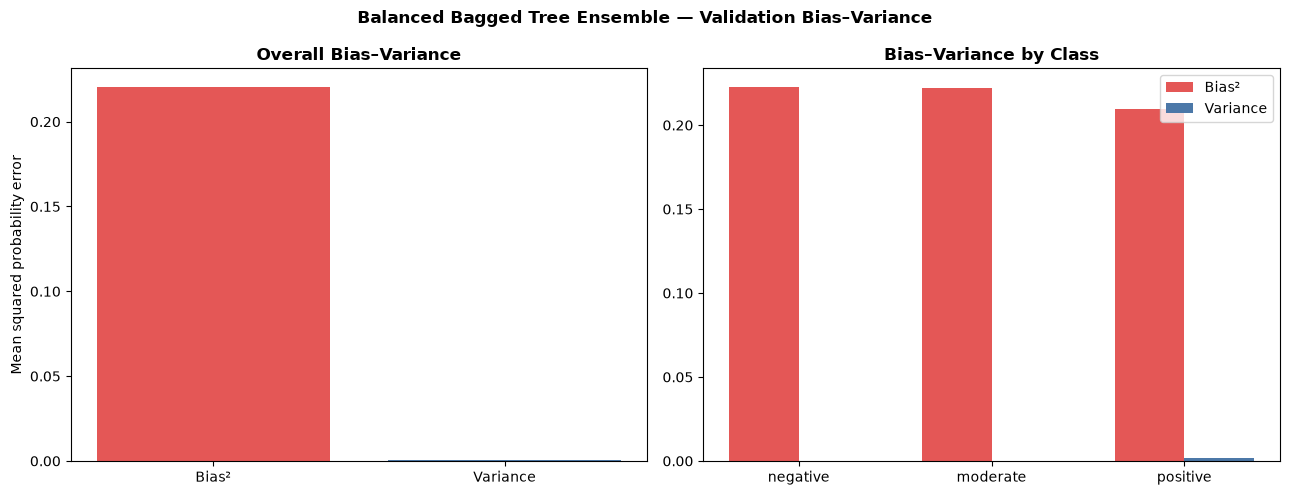

Bias²: 0.220426 | Variance: 0.000431
Graph saved to: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\bias_variance_random_forest.png


In [9]:
member_probabilities = bias_member_probabilities
member_weights = bias_member_weights
mean_probabilities = np.average(member_probabilities, axis=0, weights=member_weights)
one_hot = np.eye(len(CLASS_NAMES))[y_val]
bias_squared_samples = np.mean((mean_probabilities - one_hot) ** 2, axis=1)
per_member_squared_distance = np.mean(
    (member_probabilities - mean_probabilities[None, :, :]) ** 2, axis=2
)
variance_samples = np.average(per_member_squared_distance, axis=0, weights=member_weights)

overall_bias_squared = float(bias_squared_samples.mean())
overall_variance = float(variance_samples.mean())
class_bias = [bias_squared_samples[y_val == index].mean() for index in range(len(CLASS_NAMES))]
class_variance = [variance_samples[y_val == index].mean() for index in range(len(CLASS_NAMES))]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(['Bias²', 'Variance'], [overall_bias_squared, overall_variance],
            color=['#e45756', '#4c78a8'])
axes[0].set_title('Overall Bias–Variance', fontweight='bold')
axes[0].set_ylabel('Mean squared probability error')

positions = np.arange(len(CLASS_NAMES))
width = 0.36
axes[1].bar(positions - width/2, class_bias, width, label='Bias²', color='#e45756')
axes[1].bar(positions + width/2, class_variance, width, label='Variance', color='#4c78a8')
axes[1].set_xticks(positions)
axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_title('Bias–Variance by Class', fontweight='bold')
axes[1].legend()
fig.suptitle('Balanced Bagged Tree Ensemble — Validation Bias–Variance', fontweight='bold')
plt.tight_layout()
plt.savefig(BIAS_VARIANCE_PNG, dpi=160, bbox_inches='tight')
plt.show()
print(f'Bias²: {overall_bias_squared:.6f} | Variance: {overall_variance:.6f}')
print(f'Graph saved to: {BIAS_VARIANCE_PNG}')

## 10. Ensemble feature importance

,embedding_dimension,importance
0,ResNet18_434,0.006953
1,ResNet18_162,0.006368
2,ResNet18_81,0.006368
3,ResNet18_21,0.006010
4,ResNet18_261,0.005782
5,ResNet18_209,0.005425
6,ResNet18_330,0.005425
7,ResNet18_220,0.005425
8,ResNet18_240,0.005425
9,ResNet18_453,0.005197


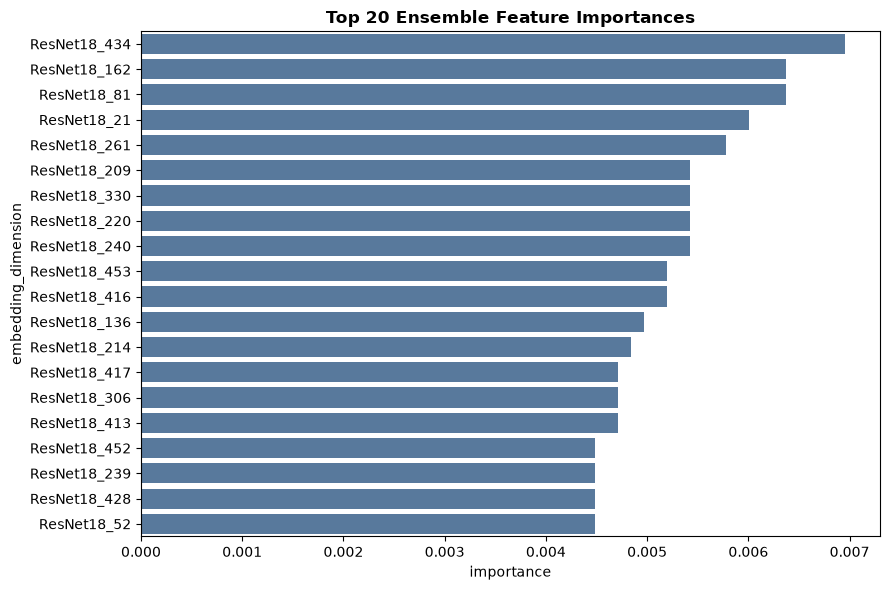

In [10]:
normalized_weights = np.asarray(selected_weights, dtype=float)
normalized_weights /= normalized_weights.sum()
ensemble_importance = np.average(
    np.stack([model.feature_importances_ for model in final_models]),
    axis=0, weights=normalized_weights
)
top_indices = np.argsort(ensemble_importance)[-20:][::-1]
importance_df = pd.DataFrame({
    'embedding_dimension': [f'ResNet18_{index}' for index in top_indices],
    'importance': ensemble_importance[top_indices],
})
display(importance_df)
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df, y='embedding_dimension', x='importance', color='#4c78a8')
plt.title('Top 20 Ensemble Feature Importances', fontweight='bold')
plt.tight_layout()
feature_importance_path = OUTPUT_DIR / 'feature_importance_random_forest.png'
plt.savefig(feature_importance_path, dpi=150, bbox_inches='tight')
plt.show()

## 11. Save the model and inference helper

In [11]:
artifact = {
    'component_models': final_models,
    'voting_weights': np.asarray(selected_weights),
    'selected_configs': selected_configs,
    'class_names': CLASS_NAMES,
    'feature_extractor': 'ImageNet pretrained ResNet18 frozen 512-D L2-normalized embedding',
    'label_source': str(label_source),
    'random_images_per_class_requested': RANDOM_IMAGES_PER_CLASS,
    'selected_real_per_class': int(final_source_summary['selected_real'][0]),
    'selected_augmented_per_class': int(final_source_summary['selected_augmented'][0]),
    'selected_total_per_class': int(final_source_summary['selected_total'][0]),
    'test_accuracy': float(test_accuracy),
    'test_balanced_accuracy': float(test_balanced_accuracy),
    'test_macro_f1': float(test_macro_f1),
    'test_real_accuracy': float(test_real_accuracy),
    'test_real_balanced_accuracy': float(test_real_balanced_accuracy),
    'test_real_macro_f1': float(test_real_macro_f1),
    'test_subject_metrics': test_subject_metrics,
    'reference_test_accuracy': REFERENCE_TEST_ACCURACY,
    'reference_test_macro_f1': REFERENCE_TEST_MACRO_F1,
}
with open(MODEL_PATH, 'wb') as file:
    pickle.dump(artifact, file)

print(f'Model saved to              : {MODEL_PATH}')
print(f'Test accuracy               : {test_accuracy:.4f}')
print(f'Test macro-F1               : {test_macro_f1:.4f}')
print(f'Real accuracy vs old RF     : {test_real_accuracy - REFERENCE_TEST_ACCURACY:+.4f}')
print(f'Real macro-F1 vs old RF     : {test_real_macro_f1 - REFERENCE_TEST_MACRO_F1:+.4f}')
print('Note: the artifact is always saved; performance is reported rather than enforced by an exception.')

def load_artifact(model_path=MODEL_PATH):
    with open(model_path, 'rb') as file:
        return pickle.load(file)

def predict_image(image_path, trained_artifact):
    with Image.open(image_path) as image:
        tensor = image_transform(image.convert('RGB')).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        if DEVICE.type == 'cuda':
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                embedding = resnet_backbone(tensor)
        else:
            embedding = resnet_backbone(tensor)
        embedding = F.normalize(embedding.float(), p=2, dim=1).cpu().numpy()
    probabilities = ensemble_predict_proba(
        trained_artifact['component_models'], trained_artifact['voting_weights'], embedding
    )[0]
    predicted_index = int(np.argmax(probabilities))
    return {
        'prediction': trained_artifact['class_names'][predicted_index],
        'confidence': float(probabilities[predicted_index]),
        'probabilities': dict(zip(
            trained_artifact['class_names'], probabilities.astype(float)
        )),
    }

# Example:
# trained_artifact = load_artifact()
# print(predict_image(PROJECT_ROOT / 'new_image.jpg', trained_artifact))

Model saved to              : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\rajuk_balanced_bagged_random_forest.pkl
Test accuracy               : 0.2361
Test macro-F1               : 0.1600
Real accuracy vs old RF     : -0.1550
Real macro-F1 vs old RF     : +0.1395
Note: the artifact is always saved; performance is reported rather than enforced by an exception.
